In [1]:
import pandas as pd
import re
from datetime import datetime
import numpy as np
from plotnine import ggplot, geom_bar, aes, geom_col, labs, theme, element_blank, element_text
import os

In [2]:
# Filters applied to NCBI Virus when downloading the metadata
# Virus/Taxonomy: Alphainfluenzavirus
# Genotype: H5N*
# Geographic Region: North America
# Host: Aves (birds)
# Collection Date: November 1, 2021 - present

In [3]:
#LATESTNCBI = "./metadata/sequence_metadata/sequence_metadata_08132024.csv"
#LATESTNCBI = "./metadata/sequence_metadata/ncbi_metadata_2022-2024.csv"
# LATESTNCBI = "./metadata/sequence_metadata/ncbi_metadata_nov2021-2024.tsv"
LATESTNCBI = "./metadata/sequence_metadata/ncbi-seq_dwld-2025-12-09_nov2021-2025.tsv"

In [4]:
data_ncbi = pd.read_csv(LATESTNCBI, sep = "\t")

/var/folders/8z/j5vh6t990rj40lqqxtsr69z00000gp/T/ipykernel_91930/1426321342.py:1: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.


In [5]:
# Function 1: Extracting strain name from GenBank Title
def strain_name(df):
    df["strain"] = df["GenBank_Title"].str.extract(pat = r"(A[\/].*[\/]\d{4})", flags = 0, expand = True)
    df["strain"] = df["strain"].str.lower()
    df["strain"] = df["strain"].str.replace("-", "")
    df["strain"] = df["strain"].str.replace("_","")
    df["strain"] = df["strain"].str.replace(" ", "")
    df["strain"] = df["strain"].str.replace("'", "") # This, specifically, should take care of "ross'sgoose" and "cooper'shawk"
    return

In [6]:
# Function 2: Detemining duplicate strains
def to_dedupe(df):
    strain_count = df["strain_segment"].value_counts()
    strain_count = strain_count.rename_axis("strain_segment").reset_index()
    duplicate_strains = []
    for strain, count in strain_count.iterrows():
        if count['count'] > 1:
            duplicate_strains.append(count['strain_segment'])
    duplicates = pd.DataFrame(duplicate_strains)
    return(duplicates)

In [7]:
#Function 3: write a new FASTA with updated header (function written by Maria)  
def fasta_writer(path, filename, df):
            
    try:  
        os.mkdir(path)

    except OSError as error:
        pass

    with open(f"{path}{filename}", "w") as f:
        for index, row in df.iterrows():
            f.write(f"{row['header']}\n")
            f.write(f"{row['sequence']}\n")

In [8]:
# Step 1: Clean and organize the metadata

In [10]:
print(len(data_ncbi))

# August 13, 2024 pull - 14,126 seq

# January 21, 2025 pull - 37,305 seq

# May 28, 2025 pull - 42,105 seq

# December 10, 2025 - 72,964 seq

72964


In [11]:
# Add the Collection_datetime column (unambiguous dates)

ncbi_filtered = data_ncbi.copy()

ncbi_filtered['Collection_datetime'] = None

for idx, i in enumerate(ncbi_filtered["Collection_Date"]):
    # Check if the date format is '%Y-%m' (e.g., '2023-03')
    try:
        if datetime.strptime(i, '%Y-%m'):
            # Convert the date to the format '%Y-%m-15' (e.g., '2023-01-15')
            formatted_date = datetime.strptime(i, '%Y-%m').strftime('%Y-%m-15')
            # Update the DataFrame with the formatted date
            ncbi_filtered.at[idx, 'Collection_datetime'] = formatted_date
    except ValueError:
        pass
        
    try:
        if datetime.strptime(i, '%Y-%m-%d'):
            formatted_date = datetime.strptime(i, '%Y-%m-%d').strftime('%Y-%m-%d')
            ncbi_filtered.at[idx, 'Collection_datetime'] = formatted_date
    except ValueError:
        pass

print(len(ncbi_filtered)) 

72964


In [12]:
# Need a column with ambiguous dates for BEAST, so adding that 

ncbi_filtered['beast_collectdate'] = None

for idx, i in enumerate(ncbi_filtered["Collection_Date"]):
    # Check if the date format is '%Y-%m' (e.g., 'Jan-2023')
    try:
        if datetime.strptime(i, '%Y-%m'):
            # Convert the date to the format '%Y-%m-XX'
            formatted_date = datetime.strptime(i, '%Y-%m').strftime('%Y-%m-XX')
            # Update the DataFrame with the formatted date
            ncbi_filtered.at[idx, 'beast_collectdate'] = formatted_date
    except ValueError:
        pass

    # Check if the date format is ''%Y-%m-%d'
    try:
        if datetime.strptime(i, '%Y-%m-%d'):
            formatted_date = datetime.strptime(i, '%Y-%m-%d').strftime('%Y-%m-%d')
            ncbi_filtered.at[idx, 'beast_collectdate'] = formatted_date
    except ValueError:
        pass

In [13]:
# Remove all dates with just year

ncbi_filtered_1 = ncbi_filtered[~ncbi_filtered["Collection_Date"].str.match(r"^\d{4}$")]

print(len(ncbi_filtered_1))

71818


In [14]:
# Make strain name in data_ncbi

ncbi_filtered_2 = ncbi_filtered_1.copy()

ncbi_filtered_2.pipe(strain_name)

In [15]:
# Make a column that combines strain_segment

ncbi_filtered_2["Segment"] = ncbi_filtered_2["Segment"].astype(str)

ncbi_filtered_2["strain_segment"] = ncbi_filtered_2[["strain", "Segment"]].apply('_'.join,axis=1)

In [16]:
# Get state from strain name

# Extract state from strain name
strain_split = ncbi_filtered_2["strain"].str.split(pat = "/", expand = True)
#print(strain_split)

# Add State to ncbi_filtered_2
ncbi_filtered_2["State"] = strain_split[2]
#ncbi_filtered_1.head()

In [19]:
state_corrections_dict = {"al":"alabama",
                          "ak":"alaska",
                          "ab":"alberta",
                          "az":"arizona",
                          "ar":"arkansas",
                          "bc":"britishcolumbia",
                          "ca":"california",
                          "co":"colorado",
                          "ct":"connecticut",
                          "districtofcolumbia":"dc",
                          "de":"delaware",
                          "fl":"florida",
                          "ga":"georgia",
                          "hi":"hawaii",
                          "id":"idaho",
                          "il":"illinois",
                          "in":"indiana",
                          "ia":"iowa",
                          "ks":"kansas",
                          "ky":"kentucky",
                          "la":"louisiana",
                          "me":"maine",
                          "mb":"manitoba",
                          "md":"maryland",
                          "ma":"massachusetts",
                          "mi":"michigan",
                          "mn":"minnesota",
                          "ms":"mississippi",
                          "mo":"missouri",
                          "mt":"montana",
                          "ne":"nebraska",
                          "nv":"nevada",
                          "nb":"newbrunswick",
                          "nl":"newfoundland",
                          "nh":"newhampshire",
                          "nj":"newjersey",
                          "nm":"newmexico",
                          "ny":"newyork",
                          "nc":"northcarolina",
                          "nd":"northdakota",
                          "nt":"northwestterritories",
                          "ns":"novascotia",
                          "nu":"nunavut",
                          "oh":"ohio",
                          "ok":"oklahoma",
                          "on":"ontario",
                          "or":"oregon",
                          "pa":"pennsylvania",
                          "pe":"princeedwardisland",
                          "pei":"princeedwardisland",
                          "pr":"puertorico",
                          "qc":"quebec",
                          "ri":"rhodeisland",
                          "sk":"saskatchewan",
                          "sc":"southcarolina",
                          "sd":"southdakota",
                          "tn":"tennessee",
                          "tx":"texas",
                          "ut":"utah",
                          "vt":"vermont",
                          "va":"virginia",
                          "wa":"washington",
                          "wv":"westvirginia",
                          "wi":"wisconsin",
                          "wy":"wyoming",
                          "yt":"yukon",
                          "louisana":"louisiana",
                          "flordia":"florida",
                          "edomex":"mexicostate",
                          "estadodemexico":"mexicostate",
                          "veracruzdeignaciodelallave":"veracruz",
                          "coahuiladezaragoza":"coahuila"
                         }

In [20]:
# Fix the State column

print(set(ncbi_filtered_2["State"]))

ncbi_stateadded = ncbi_filtered_2.copy()

ncbi_stateadded["State"] = ncbi_filtered_2["State"].map(state_corrections_dict).fillna(ncbi_stateadded["State"])

print(set(ncbi_stateadded["State"]))

{'vermont', 'oklahoma', 'maine', 'hidalgo', 'iowa', 'de', 'ns', 'temascalapa', 'ny', 'nm', 'wa', 'montana', 'flordia', 'libres', 'wi', 'mo', 'texcoco', 'newhampshire', 'guanajuato', 'nc', 'nebraska', 'oregon', 'ga', 'ohio', 'tennessee', 'morelos', 'kansas', 'nb', 'tehuitzingo', 'kentucky', 'arizona', 'me', 'veracruzdeignaciodelallave', 'on', 'lodevilla', 'co', 'la', 'oh', 'michigan', 'delaware', 'southdakota', 'sk', 'coahuiladezaragoza', 'sanluispotosi', 'northdakota', 'coahuila', 'md', 'hi', 'mb', 'virginia', 'pennsylvania', 'jojutla', 'california', 'va', 'utah', 'arkansas', 'ks', 'alberta', 'ab', 'ne', 'nan', 'massachusetts', 'jalisco', 'gomezpalacio', 'ri', 'sd', 'texas', 'florida', 'yt', 'ia', 'wv', 'ms', 'estadodemexico', 'sc', 'ar', 'fl', 'wisconsin', 'az', 'qc', 'wyoming', 'il', 'mi', 'laluz', 'louisana', 'elmarques', 'ct', 'ciudaddemexico', 'colima', 'al', 'edomex', 'missouri', 'tx', 'larimerbyc', 'durango', 'sonora', 'indiana', 'or', 'wy', 'pr', 'nh', 'veracruz', 'usa', 'color

In [21]:
# Just to check in at this point:
# I have filtered for just the sequences that have full YYYY-MM-DD dates: ncbi_filtered_1
# I have added a Collection_datetime column that is the same as Collection_date but in datetime format: ncbi_filtered_1
# I have added a column with strain title: ncbi_filtered_2
# I have added a column with strain_segment: ncbi_filtered_2
# I have added a column with corrected state data: ncbi_stateadded

In [23]:
# To make a list of bird orders included in the metadata, first determine which bird species are in the metadata
# For the most consistency, use the species defined in the strain name

ncbi_stateadded["strain_host"] = strain_split[1]

ncbi_unique_avian_hosts = pd.DataFrame(set(ncbi_stateadded["strain_host"]))

print(len(ncbi_unique_avian_hosts)) # 189 unique species names

#DATE_UPDATED = "2025-01-24"
#DATE_UPDATED = "2025-05-28"
DATE_UPDATED = "2025-12-10"

ncbi_unique_avian_hosts.to_csv("./metadata/helpful_lists/ncbi_avian_hosts_updt_" + DATE_UPDATED + ".csv", sep = ',')

189


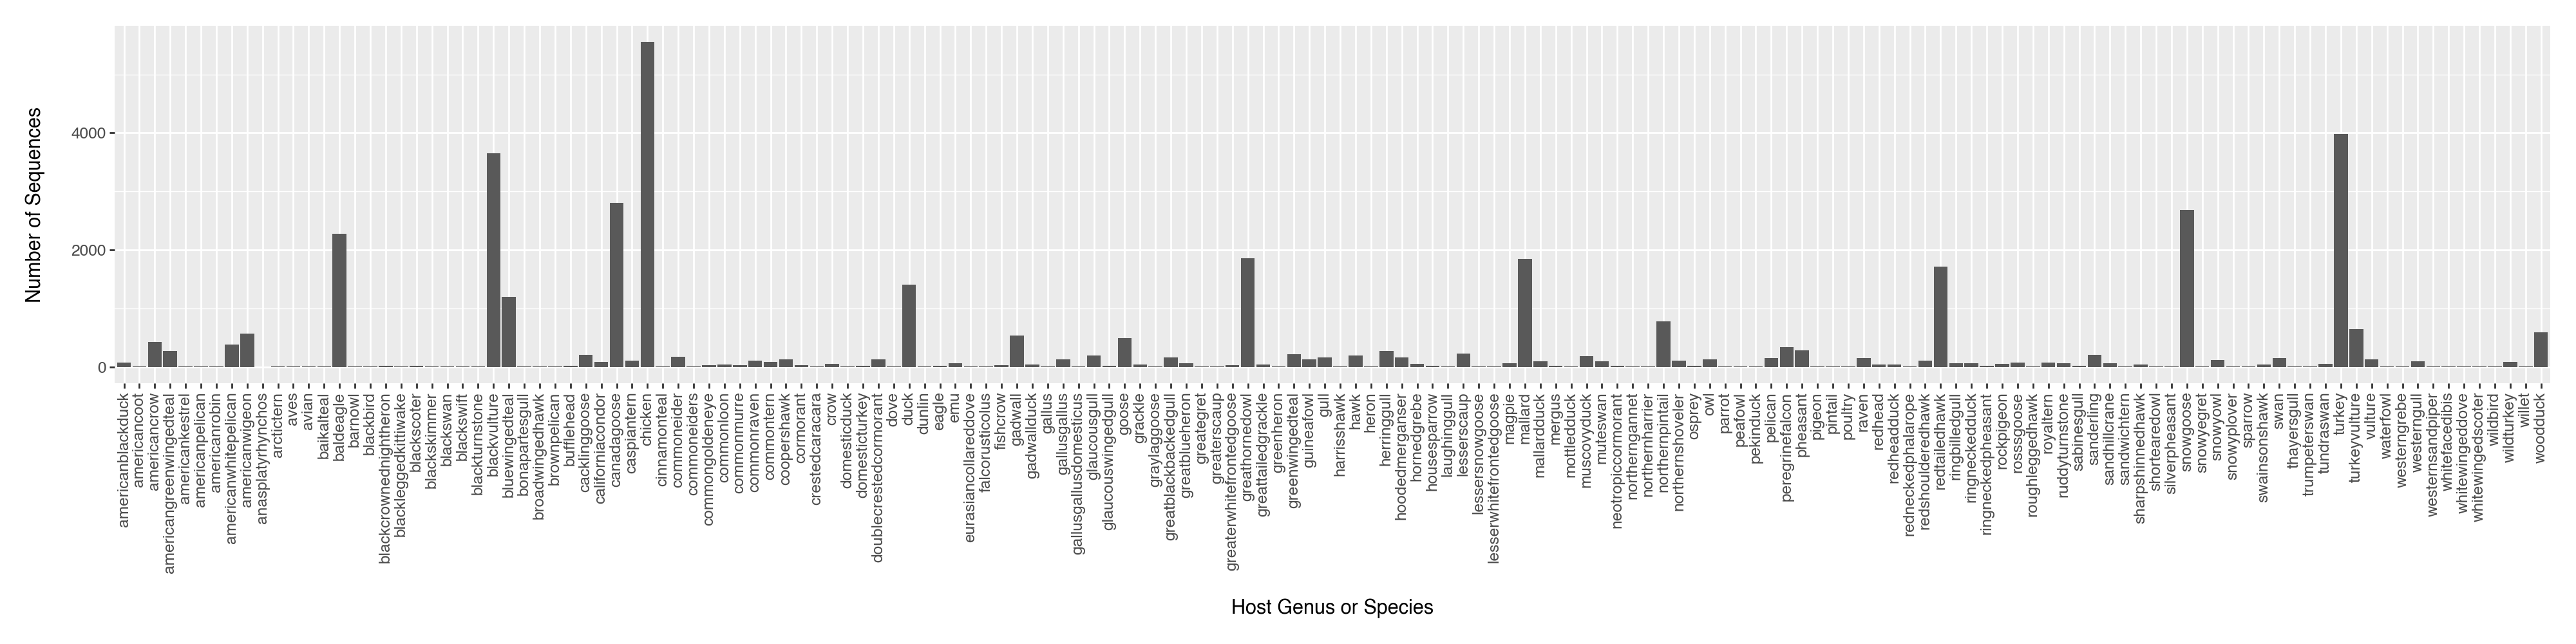

In [30]:
# Optional: make a plot of the included avian hosts

ncbi_avian_hosts = pd.DataFrame(ncbi_stateadded["strain_host"])

# plot this using ggplot
(
    ggplot(ncbi_avian_hosts, aes(x = "strain_host"))
    + geom_bar(stat = "count")
    + labs(x = "Host Genus or Species", y = "Number of Sequences")
    + theme(axis_text_x = element_text(rotation = 90))
    + theme(figure_size=(20,5))
)

In [30]:
# Add a column for host bird order and domestic status

birdies = pd.read_csv("./metadata/helpful_lists/NAm_host_list_order-domesticstat.csv", sep = ",", encoding='latin-1')

birdies_dict = birdies.set_index("strain_host").to_dict(orient="index")

ncbi_state_birdorder = ncbi_stateadded.copy()

ncbi_state_birdorder["order"] = ncbi_state_birdorder["strain_host"].map(lambda host: birdies_dict.get(host, {}).get("order"))
ncbi_state_birdorder["domesticstatus"] = ncbi_state_birdorder["strain_host"].map(lambda host: birdies_dict.get(host, {}).get("domesticstatus"))
ncbi_state_birdorder["corrected_host"] = ncbi_state_birdorder["strain_host"].map(lambda host: birdies_dict.get(host, {}).get("corrected_host"))
ncbi_state_birdorder["host_group"] = ncbi_state_birdorder["strain_host"].map(lambda host: birdies_dict.get(host, {}).get("host_group2"))

# Older method of doing the above
# for idx, row in ncbi_state_birdorder.iterrows():
#     # Check if strain_host exists in the dictionary
#     strain_host = row["strain_host"]
#     if strain_host in birdies_dict:
#         ncbi_state_birdorder.loc[idx, "order"] = birdies_dict[strain_host]["order"]
#         ncbi_state_birdorder.loc[idx, "domesticstatus"] = birdies_dict[strain_host]["domesticstatus"]
#         ncbi_state_birdorder.loc[idx, "corrected_host"] = birdies_dict[strain_host]["corrected_host"]
#         ncbi_state_birdorder.loc[idx, "host_group"] = birdies_dict[strain_host]["host_group2"]
        
print(len(ncbi_state_birdorder)) 

#Length of August 13, 2024 upload is 14102
# Length of January 21, 2025 uploade is 36820
# Length of May 25, 2025 upload is 41596
# Length of December 10, 2025 upload is 71,818

71818


In [31]:
# Check that all rows have a corresponding bird order and corrected host

empty_order = ncbi_state_birdorder[ncbi_state_birdorder["order"].isna()]
print(len(empty_order))

empty_corrected_host = ncbi_state_birdorder[ncbi_state_birdorder["corrected_host"].isna()]
print(len(empty_corrected_host))

0
0


In [32]:
# Upload a CSV with latitude, longitude, and flyway data for each location

locations_csv = "./metadata/helpful_lists/flywayregions_biggerlist.csv"

lat_long_flyways = pd.read_csv(locations_csv, sep = ',') 

# Turn this CSV into a dictionary

lat_long_flyways_dict = lat_long_flyways.set_index("location").to_dict(orient="index")

In [35]:
# Add a column for flyway and country

ncbi_state_birdorder_flyways = ncbi_state_birdorder.copy()

ncbi_state_birdorder_flyways["flyway"] = ncbi_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("flyway"))
ncbi_state_birdorder_flyways["country"] = ncbi_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("country"))

# This is an old, defunct method (because I like dictionaries more than CSVs)
# # Upload flyways dataframe
# flyways = pd.read_csv("./metadata/helpful_lists/flywayregions.csv", sep = ",", dtype={'location':str})
# column_mapper = {"location":"State"}
# flyways = flyways.rename(mapper = column_mapper, axis = 1)
# flyways["State"] = flyways["State"].str.lower()
# #flyways["State"] = flyways["State"].str.replace(pat = " ", repl = "", regex = False)

# # Add flyways to metadata
# ncbi_state_birdorder_flyways = pd.merge(ncbi_state_birdorder, flyways, on = "State", how = "outer") 

print(len(ncbi_state_birdorder_flyways)) 

# Length of August 13, 2024 upload is 14102
# Length of January 21, 2025 upload is 36820
# Length of May 25, 2025 upload is 41596
# Length of December 10, 2025 upload is 71,818

71818


In [36]:
# Add columns for latitide and longitude

ncbi_state_birdorder_flyways["latitude"] = ncbi_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("latitude"))
ncbi_state_birdorder_flyways["longitude"] = ncbi_state_birdorder_flyways["State"].map(lambda state: lat_long_flyways_dict.get(state, {}).get("longitude"))
ncbi_state_birdorder_flyways["state_coord"] = ncbi_state_birdorder_flyways["latitude"].astype(str) + ',' + ncbi_state_birdorder_flyways["longitude"].astype(str)

In [40]:
# Drop all the excess columns you made

print(ncbi_state_birdorder_flyways.columns)

drop_columns = ["Submitters", 
                "Organism_Name",
                # "Organization", 
                # "Org_location", 
                "Species",
#                "Genus", 
#                "Family", 
                "Isolate",
                "Nuc_Completeness", 
                "Geo_Location",
                "Collection_Date", 
#                "BioSample", 
                "latitude", 
                "longitude"]
ncbi_updated = ncbi_state_birdorder_flyways.drop(labels=drop_columns, axis = 1)
ncbi_updated.head()

Index(['Accession', 'GenBank_RefSeq', 'SRA_Accession', 'Organism_Name',
       'Species', 'Genotype', 'Isolate', 'Segment', 'GenBank_Title', 'Length',
       'Nuc_Completeness', 'Geo_Location', 'Country', 'USA', 'Host',
       'Tissue_Specimen_Source', 'Submitters', 'Collection_Date',
       'Release_Date', 'Collection_datetime', 'beast_collectdate', 'strain',
       'strain_segment', 'State', 'strain_host', 'order', 'domesticstatus',
       'corrected_host', 'host_group', 'flyway', 'country', 'latitude',
       'longitude', 'state_coord'],
      dtype='object')


,Accession,GenBank_RefSeq,SRA_Accession,Genotype,Segment,GenBank_Title,Length,Country,USA,Host,...,strain_segment,State,strain_host,order,domesticstatus,corrected_host,host_group,flyway,country,state_coord
0,PX661684.1,GenBank,NaN,H5N1,1,Influenza A virus (A/chicken/OR/W250070001-1/2...,2280,USA,OR,Gallus gallus,...,a/chicken/or/w2500700011/2025_1,oregon,chicken,galliformes,domestic,chicken,ground-bird,PacificFlyway,USA,"43.9336,-120.5617"
1,PX661685.1,GenBank,NaN,H5N1,2,Influenza A virus (A/chicken/OR/W250070001-1/2...,2274,USA,OR,Gallus gallus,...,a/chicken/or/w2500700011/2025_2,oregon,chicken,galliformes,domestic,chicken,ground-bird,PacificFlyway,USA,"43.9336,-120.5617"
2,PX661686.1,GenBank,NaN,H5N1,3,Influenza A virus (A/chicken/OR/W250070001-1/2...,2151,USA,OR,Gallus gallus,...,a/chicken/or/w2500700011/2025_3,oregon,chicken,galliformes,domestic,chicken,ground-bird,PacificFlyway,USA,"43.9336,-120.5617"
3,PX661687.1,GenBank,NaN,H5N1,4,Influenza A virus (A/chicken/OR/W250070001-1/2...,1704,USA,OR,Gallus gallus,...,a/chicken/or/w2500700011/2025_4,oregon,chicken,galliformes,domestic,chicken,ground-bird,PacificFlyway,USA,"43.9336,-120.5617"
4,PX661688.1,GenBank,NaN,H5N1,5,Influenza A virus (A/chicken/OR/W250070001-1/2...,1497,USA,OR,Gallus gallus,...,a/chicken/or/w2500700011/2025_5,oregon,chicken,galliformes,domestic,chicken,ground-bird,PacificFlyway,USA,"43.9336,-120.5617"


In [41]:
# Another check in:
# I have filtered for just the sequences that have full YYYY-MM-DD dates: ncbi_filtered_1
# I have added a Collection_datetime column that is the same as Collection_date but in datetime format: ncbi_filtered_1
# I have added a column with strain title: ncbi_filtered_2
# I have added a column with strain_segment: ncbi_filtered_2
# I have added a column with corrected state data: ncbi_stateadded
# I have added the corresponding host (bird) taxonomic order and domestic status: ncbi_state_birdorder
# I have addded the corresponding flyway data: ncbi_state_birdorder_flyways
# I have added the corresponding latitude and longitude: ncbi_updated

In [42]:
print(len(ncbi_updated))

71818


In [43]:
# Save as an updated TSV

#ncbi_updated.to_csv("./metadata/sequence_metadata/NCBIdata_08132024_updated.tsv", sep = '\t')
ncbi_updated.to_csv("./metadata/sequence_metadata/ncbi-seq_dwld-2025-12-09_nov2021-2025_updated.tsv", sep = '\t')

In [44]:
# Step 2: Deduplicate

In [45]:
# Check to see if each combination of strain and segment (there should be 8 segments for each strain) is unique

print(ncbi_updated["strain_segment"].is_unique)

False


In [46]:
# Which strains have to be deduplicated?

duplicates = ncbi_updated.pipe(to_dedupe)
print(duplicates)

                                             0
0    a/redheadduck/northcarolina/w2483a/2024_6
1    a/redheadduck/northcarolina/w2483a/2024_8
2        a/canadagoose/louisiana/w23902/2023_7
3        a/canadagoose/louisiana/w23902/2023_3
4        a/canadagoose/louisiana/w23902/2023_2
..                                         ...
893    a/chicken/ut/24030010002original/2024_5
894    a/chicken/ut/24030010002original/2024_6
895    a/chicken/ut/24030010002original/2024_7
896    a/chicken/ut/24030010002original/2024_8
897       a/duck/id/24028747002original/2024_6

[898 rows x 1 columns]


In [47]:
# Make a dataframe of the duplicate strains so you can remove using indexes

ncbi_duplicates = ncbi_updated[ncbi_updated['strain_segment'].isin(duplicates[0])]
#ncbi_duplicates.head()

#ncbi_duplicates.to_csv("./metadata/sequence_metadata/NCBIduplicatesonly_08132024.csv", sep = ',')
#ncbi_duplicates.to_csv("./metadata/sequence_metadata/ncbi_duplicatesonly_2022-2024.csv", sep = ',')
# ncbi_duplicates.to_csv("./metadata/sequence_metadata/ncbi_duplicatesonly_nov2021-2024.csv", sep = ',')
ncbi_duplicates.to_csv("./metadata/sequence_metadata/ncbi-seq_dwld-2025-12-09_nov2021-2025_DUPLICATESONLY.csv", sep = ',')

In [48]:
# Wild bird duplicates, as of May 25, 2025 pull
# Same wild bird duplicates in December 10, 2025 pull

# a/bald eagle/fl/w22114/2022 > keep oronasopharynx swab
# a/bluewinged teal/louisiana/ugai23893/2023 > release date of May 7, 2024 or April 23, 2024 (assembly ID)
# a/canada goose/louisiana/w23902/2023 > keep oronasopharynx swab
# a/canada goose/north carolina/w2490a/2024 > keep oronasopharynx swab
# a/commoneider/massachusetts/w22438d/2022 > same metadata
# a/greaterwhitefronted goose/louisiana/w23857a/2023 > keep oronasopharynx tissue 
# a/laughinggull/de/554/2024 > remove all (H5N9)
# a/redhead duck/north carolina/w2483a/2024 > keep oronasopharynx tissue (all clones)
# a/rockpigeon/ca/24030989002original/2024 > release date of March 4, 2025 or Feb 21, 2025 (assembly ID)
# a/rockpigeon/ca/24031704003original/2024 > release date of March 4, 2025 or Feb 21, 2025 (assembly ID)
# a/rosssgoose/kansas/w23949a/2023 > keep non-passaged segments (not a clone), all clones are from cloaca
# a/ruddyturnstone/de/549/2024 > remove all (H5N9)
# a/ruddyturnstone/de/550/2024 > remove all (H5N9)
# a/sanderling/de/530/2024 > remove all (H5N9)
# a/westerngull/ca/24036781001original/2024 > sample type is feces, release date of March 4, 2025 or Feb 21, 2025 (assembly ID)
# a/whitefacedibis/ca/24031704004original/2024 > release date of March 4, 2025 or Feb 21, 2025 (assembly ID)
# a/wood duck/georgia/w24007b/2023 > release date of April 23, 2024 (clones) or April 7, 2024 (not clones)
# a/wood duck/georgia/w24017/2023 > release date of May 4, 2024 or April 23, 2024 (assembly ID & longer seg 3 seq), all clones
# a/wood duck/north carolina/w24011a/2023 > keep longer sequence, all clones
# a/wood duck/south carolina/w24007e/2023 > same metadata, all clones > arbitrary

In [49]:
# Domestic/"unknown" bird duplicates, as of December 10, 2025

# a/chicken/ar/24038821003original/2024 > 
# a/chicken/ar/25000084002original/2024 > 
# a/chicken/ca/24035979005original/2024 > 
# a/chicken/co/24020285006original/2024 > release date of January 2, 2025 or September 25, 2024 (assembly ID)
# a/chicken/id/24028747001original/2024 > collection date of September 30, 3035 or October 18, 2024, release date of January 3, 2024 (assembly ID) or December 2, 2024 (assembly ID)
# a/chicken/id/24028747003original/2024 > collection date of September 30, 3035 or October 18, 2024, release date of January 3, 2024 (assembly ID) or December 2, 2024 (assembly ID)
# a/chicken/ut/24030010001original/2024 > release date of January 3, 3035 or December 2, 2024 (assembly ID)
# a/chicken/ut/24030010002original/2024 > release date of January 3, 3035 or December 2, 2024 (assembly ID)
# a/duck/ca/24035869002originalrepeat2/2024
# a/duck/ca/24035911001originalrepeat2/2024
# a/duck/ca/24035912001originalrepeat2/2024
# a/duck/ca/24035912002originalrepeat2/2024
# a/duck/ca/24035912003originalrepeat2/2024
# a/duck/ca/24035913001originalrepeat2/2024
# a/duck/ca/24035913004originalrepeat2/2024
# a/duck/ca/24035913005originalrepeat2/2024
# a/duck/ca/24035913007originalrepeat2/2024
# a/duck/ca/24035913008originalrepeat2/2024
# a/duck/ca/24035913009originalrepeat2/2024
# a/duck/ca/24035915001originalrepeat2/2024
# a/duck/ca/24035915002originalrepeat2/2024
# a/duck/ca/24035915003originalrepeat2/2024
# a/duck/ca/24035915004originalrepeat2/2024
# a/duck/ca/24035915005originalrepeat2/2024
# a/duck/ca/24035915006originalrepeat2/2024
# a/duck/id/24028747002original/2024 > collection date of September 20, 2024 or October 18, 2024, release date of January 3, 2024 (assembly ID) or December 2, 2024 (assembly ID)
# a/duck/il/25000057001original/2024
# a/duck/il/25000059001original/2024
# a/duck/il/25000060001original/2024
# a/duck/tn/24038885003original/2024
# a/duck/tn/24038885004original/2024
# a/duck/tx/25000377001original/2025
# a/emu/ca/24031663001original/2024 > release date of January 3, 3035 or December 6, 2024 (assembly ID)
# a/emu/ca/24031663002original/2024 > release date of January 3, 3035 or December 6, 2024 (assembly ID)
# a/emu/ca/24031663003original/2024 > release date of January 3, 3035 or December 6, 2024 (assembly ID)
# a/guineafowl/ks/24038653003original/2024 > 
# a/guineafowl/mo/24038441003original/2024
# a/guineafowl/mo/24038546002original/2024
# a/guineafowl/sd/25000286001original/2025
# a/guineafowl/wv/25000050001original/2024
# a/peafowl/sd/25000286003original/2025
# a/pheasant/ca/25000138001original/2024
# a/pheasant/ca/25000138002original/2024
# a/pheasant/ca/25000138003original/2024
# a/pheasant/ca/25000138004original/2024
# a/pheasant/ca/25000138005original/2024
# a/pheasant/ca/25000138006original/2024
# a/pheasant/sc/24039001001original/2024
# a/pheasant/sd/24038918001original/2024
# a/turkey/ca/24030170001original/2024 > release date of January 3, 3035 or December 6, 2024 (assembly ID)
# a/turkey/id/24028305001original/2024 > release date of January 3, 2025 or November 13, 2024 (assembly ID)
# a/turkey/id/24028305002original/2024 > release date of January 3, 2025 or November 13, 2024 (assembly ID)
# a/turkey/id/24028518001original/2024 > collection date of September 26, 2024 or October 18, 2024, release date of January 3, 2024 (assembly ID) or December 2, 2024 (assembly ID)
# a/turkey/id/25000070001original/2024
# a/turkey/id/25000070002original/2024
# a/turkey/id/25000070003original/2024
# a/turkey/il/24038393001original/2024
# a/turkey/il/24038393002original/2024
# a/turkey/il/24038393003original/2024
# a/turkey/il/24038393004original/2024
# a/turkey/in/25000295001original/2025
# a/turkey/in/25000295002original/2025
# a/turkey/in/25000295003original/2025
# a/turkey/in/25000295004original/2025
# a/turkey/mi/24038285001original/2024
# a/turkey/mi/24038977001original/2024
# a/turkey/mi/24038977002original/2024
# a/turkey/mi/24038978001original/2024
# a/turkey/mi/24038978002original/2024
# a/turkey/mi/24038979001original/2024
# a/turkey/mi/24038979002original/2024
# a/turkey/mi/25000204001original/2025
# a/turkey/mi/25000204002original/2025
# a/turkey/mi/25000205001original/2025
# a/turkey/mi/25000205002original/2025
# a/turkey/mo/24038169001original/2024
# a/turkey/mo/24038169002original/2024
# a/turkey/mo/24038618001original/2024
# a/turkey/mo/24038618002original/2024
# a/turkey/ne/24036225001originalrepeat/2024
# a/turkey/ne/24036225002originalrepeat2/2024
# a/turkey/oh/25000542001original/2025
# a/turkey/oh/25000542002original/2025
# a/turkey/ok/24038440005original/2024
# a/turkey/ok/24038440009original/2024
# a/turkey/ok/24038440010original/2024
# a/turkey/ok/24038442001original/2024
# a/turkey/ok/24038442002original/2024
# a/turkey/ok/24038442003original/2024
# a/turkey/ok/24038442004original/2024
# a/turkey/wi/24038658001original/2024
# a/turkey/wi/24038658002original/2024
# a/turkey/wv/25000051001original/2024

In [50]:
# Categorize duplicate strains into groups based on how you are going to deduplicate them

# For group 1, I want to keep the oronasopharynx swabs
group_1 = ["a/baldeagle/fl/w22114/2022", "a/canadagoose/louisiana/w23902/2023", "a/canadagoose/northcarolina/w2490a/2024", 
           "a/greaterwhitefrontedgoose/louisiana/w23857a/2023", "a/redheadduck/northcarolina/w2483a/2024"]

# For group 2, I want to keep the duplicates with the less recent release date (which is also the duplicate with an assembly ID)
group_2 = ["a/bluewingedteal/louisiana/ugai23893/2023", "a/woodduck/georgia/w24017/2023", 
           "a/rockpigeon/ca/24030989002original/2024", "a/rockpigeon/ca/24031704003original/2024",
           "a/westerngull/ca/24036781001original/2024", "a/whitefacedibis/ca/24031704004original/2024"
          ]

# For group 3, some duplicates are clones and some are non-passaged segments > just going to drop all
group_3 = ["a/rosssgoose/kansas/w23949a/2023", "a/woodduck/georgia/w24007b/2023"]


# For group 4, duplicates have different sequence lengths > just going to drop all
group_4 = ["a/woodduck/northcarolina/w24011a/2023"]

# For group 5, the metadata is all the same, so I want to keep the first instance
group_5 = ["a/woodduck/southcarolina/w24007e/2023", "a/commoneider/massachusetts/w22438d/2022"]

In [54]:
dates_test = ["2024-05-07", "2024-04-23"]

print(min(dates_test))

2024-04-23


In [72]:
# Function: to deduplicate all the MANY, silly duplicates

def deduplicating_ncbi(duplicates_df):

    # Set up a couple of open lists
    indexes_to_drop = []
    not_wild = []
    not_n1 = []
    group_1_rows = []
    group_2_rows = []
    group_3_rows = []
    group_4_rows = []
    group_5_rows = []

    # Make groups depending on the type of duplicate
    for idx, row in duplicates_df.iterrows():
        strain = row["strain"]
        domestic_status = row["domesticstatus"]
        na_type = row["Genotype"]
        
        if domestic_status != "wild":
            not_wild.append(row)
        elif na_type != "H5N1":
            not_n1.append(row)
        elif strain in group_1:
            group_1_rows.append(row)
        elif strain in group_2:
            group_2_rows.append(row)
        elif strain in group_3:
            group_3_rows.append(row)
        elif strain in group_4:
            group_4_rows.append(row)
        elif strain in group_5:
            group_5_rows.append(row)
        elif strain in group_6:
            group_6_rows.append(row)
        else:
            print(f"duplicates of {strain} are ungrouped")

    # Turn all groups into dataframes
    not_wild_df = pd.DataFrame(not_wild)
    not_n1_df = pd.DataFrame(not_n1)
    group_1_rows_df = pd.DataFrame(group_1_rows)
    group_2_rows_df = pd.DataFrame(group_2_rows)
    group_3_rows_df = pd.DataFrame(group_3_rows)
    group_4_rows_df = pd.DataFrame(group_4_rows)
    group_5_rows_df = pd.DataFrame(group_5_rows)

    # For each groupded dataframe, add the index of rows to be dropped to indexes_to_drop
    for idx, row in not_wild_df.iterrows():
        indexes_to_drop.append(idx)

    for idx, row in not_n1_df.iterrows():
        indexes_to_drop.append(idx)
    
    for idx, row in group_1_rows_df.iterrows(): # group 1: keep oronasopharynx duplicates
        if row["Tissue_Specimen_Source"] != "oronasopharynx":
            indexes_to_drop.append(idx)
        else:
            pass
    
    # for idx, row in group_2_rows_df.iterrows(): # group 2: remove the more recent release date/duplicates with no assembly ID
    #     if pd.isna(row["Assembly"]):
    #         indexes_to_drop.append(idx)
    #     else:
    #         pass

    for idx, row in group_2_rows_df.iterrows(): # group 2: remove the more recent release date
        if max(group_2_rows_df["Release_Date"]):
            indexes_to_drop.append(idx)
        else:
             pass

    for idx, row in group_3_rows_df.iterrows(): # group 3: drop all
        indexes_to_drop.append(idx)

    for idx, row in group_4_rows_df.iterrows(): # group 4: drop all
        indexes_to_drop.append(idx)

    seen_strains = set()
    for idx, row in group_5_rows_df.iterrows(): # group 5: keep the first instance
        if row["strain_segment"] in seen_strains:
            indexes_to_drop.append(idx)
        else:
            seen_strains.add(row["strain_segment"])

    return(indexes_to_drop)

In [73]:
# Use the above function to add the indexes you want to remove to ncbi_remove 

ncbi_remove = deduplicating_ncbi(ncbi_duplicates)

print(len(ncbi_remove))

1790


In [74]:
# Remove duplicates by their indexes

ncbi_updated_deduped = ncbi_updated.drop(labels = ncbi_remove, axis = 0)

In [75]:
# Make sure the following columns are strings
# This will be necessary later when making new FASTA headers

ncbi_updated_deduped["strain"] = ncbi_updated_deduped["strain"].astype(str)
ncbi_updated_deduped["beast_collectdate"] = ncbi_updated_deduped["beast_collectdate"].astype(str)
ncbi_updated_deduped["domesticstatus"] = ncbi_updated_deduped["domesticstatus"].astype(str)
ncbi_updated_deduped["order"] = ncbi_updated_deduped["order"].astype(str)
ncbi_updated_deduped["flyway"] = ncbi_updated_deduped["flyway"].astype(str)

In [77]:
print(len(ncbi_updated_deduped))

# August 13, 2024 pull - ~13,000 seqs
# January 21, 2025 pull - 36,489 seqs
# May 25, 2025 pull - 40,089
# December 10, 2025 pull - 70,028 seqs

print(ncbi_updated_deduped["strain_segment"].is_unique)

70028
True


In [78]:
# Save as TSV
#ncbi_updated_deduped.to_csv("./metadata/sequence_metadata/NCBIdata_08132024_updated_deduped.tsv", sep = '\t')
#ncbi_updated_deduped.to_csv("./metadata/sequence_metadata/ncbi_2022-2024_updated_deduped.tsv", sep = '\t')
# ncbi_updated_deduped.to_csv("./metadata/sequence_metadata/ncbi_nov2021-2024_updated_deduped.tsv", sep = '\t')
ncbi_updated_deduped.to_csv("./metadata/sequence_metadata/ncbi-seq_dwld-2025-12-09_nov2021-2025_updated_deduped.tsv", sep = '\t')

In [79]:
# Step 3: split into segments

In [81]:
# Split metadata file into separate files by segment

segment_pb2 = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '1'] # Encodes PB2 
segment_pb1 = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '2'] # Encodes PB1 and sometimes PB1-F2
segment_pa = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '3'] # Encodes PA
segment_ha = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '4'] # Encodes HA
segment_np = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '5'] # Encodes NP
segment_na = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '6'] # Encodes NA
segment_m = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '7'] # Encodes M1 matrix
segment_ns = ncbi_updated_deduped[ncbi_updated_deduped["Segment"] == '8'] # Encodes NS1, NEP, and NS2

print(len(segment_pb2))
print(len(segment_pb1))
print(len(segment_pa))
print(len(segment_ha))
print(len(segment_np))
print(len(segment_na))
print(len(segment_m))
print(len(segment_ns))

# August 13, 2024 pull - Adds up to 13533 (in order: 1724, 1730, 1737, 1757, 1753, 1754, 1754, 1756)
# January 21, 2025 pull - Adds up to 36,489 (in order: 4541, 4546, 4553, 4572, 4569, 4566, 4570, 4572)
# March 25, 2025 pull - Adds up to 40,089 (in order: 4990, 4996, 5003, 5023, 5019, 5016, 5020, 5022)
# December 10, 2025 pull - Adds up to 70,028 (in order: 8728, 8731, 8739, 8769, 8764, 8765, 8765, 8767)

8728
8731
8739
8769
8764
8765
8765
8767


In [82]:
# Save segment as TSVs

# segment_pb2.to_csv("./metadata/sequence_metadata/ncbi_pb2_08132024.tsv", sep='\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/ncbi_pb1_08132024.tsv", sep='\t')
# segment_pa.to_csv("./metadata/sequence_metadata/ncbi_pa_08132024.tsv", sep='\t')
# segment_ha.to_csv("./metadata/sequence_metadata/ncbi_ha_08132024.tsv", sep='\t')
# segment_np.to_csv("./metadata/sequence_metadata/ncbi_np_08132024.tsv", sep='\t')
# segment_na.to_csv("./metadata/sequence_metadata/ncbi_na_08132024.tsv", sep='\t')
# segment_m.to_csv("./metadata/sequence_metadata/ncbi_m_08132024.tsv", sep='\t')
# segment_ns.to_csv("./metadata/sequence_metadata/ncbi_ns_08132024.tsv", sep='\t')

# segment_pb2.to_csv("./metadata/sequence_metadata/ncbi_pb2_2022-2024.tsv", sep='\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/ncbi_pb1_2022-2024.tsv", sep='\t')
# segment_pa.to_csv("./metadata/sequence_metadata/ncbi_pa_2022-2024.tsv", sep='\t')
# segment_ha.to_csv("./metadata/sequence_metadata/ncbi_ha_2022-2024.tsv", sep='\t')
# segment_np.to_csv("./metadata/sequence_metadata/ncbi_np_2022-2024.tsv", sep='\t')
# segment_na.to_csv("./metadata/sequence_metadata/ncbi_na_2022-2024.tsv", sep='\t')
# segment_m.to_csv("./metadata/sequence_metadata/ncbi_m_2022-2024.tsv", sep='\t')
# segment_ns.to_csv("./metadata/sequence_metadata/ncbi_ns_2022-2024.tsv", sep='\t')

# segment_pb2.to_csv("./metadata/sequence_metadata/ncbi_pb2_nov2021-2024.tsv", sep='\t')
# segment_pb1.to_csv("./metadata/sequence_metadata/ncbi_pb1_nov2021-2024.tsv", sep='\t')
# segment_pa.to_csv("./metadata/sequence_metadata/ncbi_pa_nov2021-2024.tsv", sep='\t')
# segment_ha.to_csv("./metadata/sequence_metadata/ncbi_ha_nov2021-2024.tsv", sep='\t')
# segment_np.to_csv("./metadata/sequence_metadata/ncbi_np_nov2021-2024.tsv", sep='\t')
# segment_na.to_csv("./metadata/sequence_metadata/ncbi_na_nov2021-2024.tsv", sep='\t')
# segment_m.to_csv("./metadata/sequence_metadata/ncbi_m_nov2021-2024.tsv", sep='\t')
# segment_ns.to_csv("./metadata/sequence_metadata/ncbi_ns_nov2021-2024.tsv", sep='\t')

segment_pb2.to_csv("./metadata/sequence_metadata/ncbi_pb2_nov2021-2025.tsv", sep='\t')
segment_pb1.to_csv("./metadata/sequence_metadata/ncbi_pb1_nov2021-2025.tsv", sep='\t')
segment_pa.to_csv("./metadata/sequence_metadata/ncbi_pa_nov2021-2025.tsv", sep='\t')
segment_ha.to_csv("./metadata/sequence_metadata/ncbi_ha_nov2021-2025.tsv", sep='\t')
segment_np.to_csv("./metadata/sequence_metadata/ncbi_np_nov2021-2025.tsv", sep='\t')
segment_na.to_csv("./metadata/sequence_metadata/ncbi_na_nov2021-2025.tsv", sep='\t')
segment_m.to_csv("./metadata/sequence_metadata/ncbi_m_nov2021-2025.tsv", sep='\t')
segment_ns.to_csv("./metadata/sequence_metadata/ncbi_ns_nov2021-2025.tsv", sep='\t')

In [66]:
# Step 4: Make FASTA headers for each segment

In [67]:
#read FASTA as dataframe (code courtesy of Maria)
FASTANAME = "./raw_data/ncbi_sequences_nov2021-2024.fasta"

fasta_data = []
    
with open(FASTANAME) as f:
    header = ""
    sequence = ""
    for line in f:
        if line.startswith(">"):
            if header != "":
                fasta_data.append({"header": header, "sequence": sequence})
            header = line.strip() 
            sequence = ""
        else:
            sequence += line.strip()
    fasta_data.append({"header": header, "sequence": sequence}) #last line

fasta_df = pd.DataFrame(fasta_data)

print(fasta_df.head())

                                              header  \
0  >PV643466.1 |Influenza A virus (A/chicken/Ohio...   
1  >PV643467.1 |Influenza A virus (A/chicken/Ohio...   
2  >PV643468.1 |Influenza A virus (A/chicken/Ohio...   
3  >PV643469.1 |Influenza A virus (A/chicken/Ohio...   
4  >PV643470.1 |Influenza A virus (A/chicken/Ohio...   

                                            sequence  
0  ATGGAGAACATAGTACTACTTCTTGCAATAGTTAGTCTTGTTAAAA...  
1  ATGAGTCTTCTAACCGAGGTCGAAACGTACGTTCTCTCTATCGTCC...  
2  ATGAATCCAAATCAAAAGATAACAACCATTGGATCAATCTGTATGG...  
3  ATGGATTCCAACACTGTGTCAAGCTTTCAGGTAGACTGCTTTCTTT...  
4  ATGGCGTCTCAAGGCACCAAACGATCCTATGAACAAATGGAAACTG...  


In [68]:
#split header into two columns

fa_header_split = fasta_df["header"].str.split(pat = '|', expand = True)
fasta_df["Accession"] = fa_header_split[0]

fasta_df["Accession"] = fasta_df["Accession"].str.replace(">", "")
fasta_df["Accession"] = fasta_df["Accession"].str.replace(".1", "")
fasta_df["Accession"] = fasta_df["Accession"].str.strip()

print(fasta_df.head())
#get rid of second half, new column with just accession

                                              header  \
0  >PV643466.1 |Influenza A virus (A/chicken/Ohio...   
1  >PV643467.1 |Influenza A virus (A/chicken/Ohio...   
2  >PV643468.1 |Influenza A virus (A/chicken/Ohio...   
3  >PV643469.1 |Influenza A virus (A/chicken/Ohio...   
4  >PV643470.1 |Influenza A virus (A/chicken/Ohio...   

                                            sequence Accession  
0  ATGGAGAACATAGTACTACTTCTTGCAATAGTTAGTCTTGTTAAAA...  PV643466  
1  ATGAGTCTTCTAACCGAGGTCGAAACGTACGTTCTCTCTATCGTCC...  PV643467  
2  ATGAATCCAAATCAAAAGATAACAACCATTGGATCAATCTGTATGG...  PV643468  
3  ATGGATTCCAACACTGTGTCAAGCTTTCAGGTAGACTGCTTTCTTT...  PV643469  
4  ATGGCGTCTCAAGGCACCAAACGATCCTATGAACAAATGGAAACTG...  PV643470  


In [70]:
# Make a FASTA with a new header for each gene

list_of_genes = ["pb2", "pb1", "pa", "ns", "np", "na", "m", "ha"]
DATE = "nov2021-2024"

genes = list_of_genes

for gene in genes:

    file_path = f"./metadata/sequence_metadata/ncbi_{gene}_{DATE}.tsv"
    meta_df = pd.read_csv(file_path, sep = '\t')

    output = "NCBIsequence_" + gene + "_" + DATE + ".fasta"
    
    merged_meta_fasta = meta_df.merge(fasta_df, how = "inner", on = "Accession")
    new_fasta = merged_meta_fasta.copy()
    
    new_fasta["header"] = merged_meta_fasta[["strain", "beast_collectdate", "domesticstatus", "order", "flyway"]].astype(str).apply('|'.join, axis=1)
    new_fasta["header"] = ">" + new_fasta["header"]
    fasta_writer("./raw_data/", output, new_fasta)